# [OUR PROPOSED] Hilbert RGBA PNG 2D Residual U-Net (`Hilbert-ResUNet2D`)
### Lossless Signal-to-Image (`32×32×4` RGBA PNG) EEG Denoising for EOG Ocular Artifact Removal (`fs = 256 Hz`, `512` Samples)

---

### Abstrak & Gambaran Metodologi Usulan:
Elektroensefalografi (EEG) adalah modalitas krusial dalam neurosains dan *Brain-Computer Interface* (BCI). Namun, rekaman EEG sangat rentan terkontaminasi oleh artefak okular (*Electrooculogram* / EOG) akibat kedipan dan pergerakan bola mata yang memiliki amplitudo tinggi ($>100\text{ }\mu\text{V}$) dan terkonsentrasi pada pita frekuensi rendah ($<8\text{ Hz}$, tumpang tindih dengan ritme Delta dan Theta otak).

Notebook ini mengikuti alur eksperimen lengkap dari referensi `ha-resunet2d-eog.ipynb` dengan mengganti metode pengubahan sinyal 1D ke citra 2D menggunakan **Hilbert Curve Bit-Packing RGBA PNG (`hilbert_png_codec.py`)**:

1. **Representasi Citra 2D Lossless (`32×32×4` RGBA PNG via Kurva Hilbert)**:
   - Setiap sampel sinyal `float32` (`<f4`) panjang dinamis $N \in [1, 1023]$ (pada dataset ini $N = 512$) dikemas menjadi 4 byte kanal `RGBA` (`uint8`) mengikuti jalur kurva Hilbert 2D berdimensi file PNG konstan `32×32×4`.
   - Piksel Hilbert terakhir `(0, 31)` menyimpan metadata panjang sinyal asli $N$ (`<u4`) sehingga dapat di-decode kembali secara **100% lossless bit-exact** ($\text{max } |error| = 0.0$) dari file PNG fisik maupun buffer memori.
   - Saat masuk ke model 2D, RGBA PNG didecode menjadi tensor 2-kanal `(2, 32, 32)` berisi `[signal, active_mask]`.

2. **Masked Reversible Instance Normalization (Masked RevIN)**:
   - Menghitung rata-rata dan standar deviasi per sampel **hanya pada piksel aktif** (`active_mask == 1`) agar area non-aktif bernilai nol tidak mendistorsi statistik amplitudo.

3. **Inovasi 1 — Hilbert-Locality 2D Residual Encoder-Decoder + Squeeze-and-Excitation (`SEBlock2D`)**:
   - Dual-scale 2D Stem (`3×3` + `5×5`), `ResBlock2D`, dan `SEBlock2D` pada grid Hilbert `32×32`.
   - Downsampling isotropik `(2, 2)` (`32×32 -> 16×16 -> 8×8`) mempertahankan lokalitas blok waktu berurutan di sepanjang kurva Hilbert secara eksak.

4. **Inovasi 2 — Chronological Hilbert 64-Token BiLSTM + Pre-Norm Transformer Self-Attention Bottleneck**:
   - Pada resolusi bottleneck `8×8`, fitur diurutkan mengikuti kurva Hilbert tingkat-8 (`hilbert_indices(8)`) menjadi 64 token **kronologis berurutan** lalu diproses oleh **BiLSTM 2-Layer** dan **Transformer Encoder**.

5. **Inovasi 3 — Dual-Domain Hilbert Spectral Gate (`HilbertSpectralGate1D` via rFFT)**:
   - Mengekstrak fitur sepanjang urutan kurva Hilbert aktif (`hilbert_indices(32)`), menyaring komponen frekuensi artefak EOG di domain Fourier secara paralel, lalu memetakannya kembali ke grid 2D.

6. **Strategi Pelatihan Multi-Domain, GPU Cross-Pairing & Evaluasi End-to-End PNG**:
   - **Multi-Domain Loss** pada sampel aktif kurva Hilbert: $\mathcal{L} = \text{Scale-Norm L1} + 3.5 \times (1 - \text{CC}) + 0.25 \times \text{L1}_{\text{FFT}}$.
   - **Dynamic Cross-Pairing Augmentation** di GPU serta verifikasi evaluasi uji melalui alur penuh **Sinyal → Hilbert RGBA PNG → Inferensi → Hilbert RGBA PNG → Sinyal**.


In [1]:
# ==============================================================================
# 1. SETUP ENVIRONMENT, SEED DETERMINISTIK & IMPOR MODUL
# ==============================================================================
import os, io, math, time, random
from functools import lru_cache
from pathlib import Path
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.model_selection import train_test_split
from scipy.signal import butter, filtfilt
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_all_seeds(SEED)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")
if device.type == "cuda":
    gpu_count = torch.cuda.device_count()
    print(f"GPU    : {torch.cuda.get_device_name(0)} (count={gpu_count})")
    for idx in range(gpu_count):
        print(f"  [{idx}] {torch.cuda.get_device_name(idx)}")


Device : cuda
GPU    : NVIDIA GeForce GTX 1650 (count=1)
  [0] NVIDIA GeForce GTX 1650


In [2]:
# ==============================================================================
# 2. PEMUATAN DATASET EEGDENOISENET (ARTEFAK EOG)
# ==============================================================================
ARTIFACT_TYPE = "eog"
FS = 256  # Frekuensi sampling pipeline EOG

possible_paths = [
    os.path.abspath(os.path.join(os.getcwd(), "Dataset", ARTIFACT_TYPE.upper())),
    os.path.abspath(os.path.join(os.getcwd(), "Dataset", ARTIFACT_TYPE)),
    os.path.abspath(os.path.join(os.getcwd(), "..", "Dataset", ARTIFACT_TYPE.upper())),
    f"/kaggle/input/syntetic-data-construction/processed/{ARTIFACT_TYPE}",
    f"/kaggle/input/syntetic-data-constructionprocessed/{ARTIFACT_TYPE}",
    f"/kaggle/input/notebooks/akipss/syntetic-data-construction/processed/{ARTIFACT_TYPE}",
    f"/kaggle/input/synthetic-data-construction/processed/{ARTIFACT_TYPE}",
    os.path.join("D:\\riset", "data", "kaggle-ds", "processed", ARTIFACT_TYPE),
    os.path.abspath(os.path.join(os.getcwd(), "processed", ARTIFACT_TYPE)),
    os.path.abspath(os.path.join(os.getcwd(), "..", "processed", ARTIFACT_TYPE)),
    os.path.abspath(os.path.join(os.getcwd(), "..", "..", "processed", ARTIFACT_TYPE)),
    os.path.join("D:\\Signal Image Denoising", "processed", ARTIFACT_TYPE),
]
base_dir = next((p for p in possible_paths if os.path.exists(os.path.join(p, "clean_eeg_all_epochs.npy"))), None)
if base_dir is None and os.path.exists("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "clean_eeg_all_epochs.npy" in files and ARTIFACT_TYPE in root.lower():
            base_dir = root
            break
assert base_dir is not None, f"Dataset {ARTIFACT_TYPE} tidak ditemukan!"
print(f"Dataset path: {base_dir}")

clean_data = np.load(os.path.join(base_dir, "clean_eeg_all_epochs.npy")).astype(np.float32)
contaminated_dict = np.load(os.path.join(base_dir, "linear_synthetic.npy"), allow_pickle=True).item()
SNR_KEYS = sorted(contaminated_dict.keys())
SIGNAL_LENGTH = int(clean_data.shape[-1])

print(f"Clean EEG shape : {clean_data.shape} (N={clean_data.shape[0]} epochs, L={SIGNAL_LENGTH} samples)")
print(f"SNR Levels      : {SNR_KEYS} dB")


Dataset path: d:\Tsaqib\Dataset\EOG
Clean EEG shape : (3400, 512) (N=3400 epochs, L=512 samples)
SNR Levels      : [-7, -6, -5, -4, -3, -2, -1, 0, 1, 2] dB


In [3]:
# ==============================================================================
# 3. PEMBAGIAN DATA DETERMINISTIK (70% TRAIN / 15% VAL / 15% TEST)
# ==============================================================================
n_samples = len(clean_data)
indices = np.arange(n_samples)
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED)

clean_train = clean_data[train_idx].astype(np.float32)
clean_val   = clean_data[val_idx].astype(np.float32)
clean_test  = clean_data[test_idx].astype(np.float32)

contaminated_train = {s: contaminated_dict[s][train_idx].astype(np.float32) for s in SNR_KEYS}
contaminated_val   = {s: contaminated_dict[s][val_idx].astype(np.float32) for s in SNR_KEYS}
contaminated_test  = {s: contaminated_dict[s][test_idx].astype(np.float32) for s in SNR_KEYS}

print(f"Pembagian Sampel (0% Data Leakage):")
print(f"  - Train Set : {len(train_idx)} subjek/epoch ({len(train_idx)/n_samples*100:.1f}%)")
print(f"  - Val Set   : {len(val_idx)} subjek/epoch ({len(val_idx)/n_samples*100:.1f}%)")
print(f"  - Test Set  : {len(test_idx)} subjek/epoch ({len(test_idx)/n_samples*100:.1f}%)")
assert len(np.intersect1d(train_idx, test_idx)) == 0
assert len(np.intersect1d(val_idx, test_idx)) == 0


Pembagian Sampel (0% Data Leakage):
  - Train Set : 2380 subjek/epoch (70.0%)
  - Val Set   : 510 subjek/epoch (15.0%)
  - Test Set  : 510 subjek/epoch (15.0%)


In [4]:
# ==============================================================================
# 4. PEMBENTUKAN PASANGAN DATA & DYNAMIC CROSS-PAIRING AUGMENTATION (GPU)
# ==============================================================================
X_pair = np.concatenate([contaminated_train[s] for s in SNR_KEYS], axis=0).astype(np.float32)
Y_pair = np.concatenate([clean_train] * len(SNR_KEYS), axis=0).astype(np.float32)
A_pair = X_pair - Y_pair

X_val = torch.tensor(np.concatenate([contaminated_val[s] for s in SNR_KEYS], axis=0).astype(np.float32), device=device)
Y_val = torch.tensor(np.concatenate([clean_val] * len(SNR_KEYS), axis=0).astype(np.float32), device=device)

# Bank sinyal training terisolasi murni (0% leakage ke val/test)
CLEAN_BANK_TR = torch.tensor(clean_train, dtype=torch.float32, device=device)
ART_BANK_TR   = torch.tensor(contaminated_train[0] - clean_train, dtype=torch.float32, device=device)
SNR_TENSOR    = torch.tensor(SNR_KEYS, dtype=torch.float32, device=device)

def _batch_circular_shift(x, max_shift=SIGNAL_LENGTH):
    """Pergeseran waktu melingkar acak independen per sampel."""
    B, L = x.shape
    shifts = torch.randint(0, max_shift, (B, 1), device=x.device)
    idx = (torch.arange(L, device=x.device).unsqueeze(0) - shifts) % L
    return torch.gather(x, 1, idx)

def build_epoch_gpu(cross_pair_prob=0.75, alpha_jitter=0.20, do_shift=True):
    """
    Generator pasangan data latih GPU dinamis:
    - 75% sampel menggunakan Dynamic Cross-Pairing antara clean_train[i] dan art_train[j] acak.
    - 25% sampel mempertahankan pasangan asli + jitter skala (+-20%) dan pergeseran waktu melingkar.
    - Menghasilkan >5.6 juta kombinasi unik yang mencegah overfitting pada model kapasitas besar.
    """
    n_clean = len(CLEAN_BANK_TR)
    n_snr = len(SNR_KEYS)
    total = n_clean * n_snr

    clean_idx = torch.arange(n_clean, device=device).repeat(n_snr)
    Y = CLEAN_BANK_TR[clean_idx].clone()

    rand_art_idx = torch.randint(0, n_clean, (total,), device=device)
    use_cross = (torch.rand(total, device=device) < cross_pair_prob)
    art_idx = torch.where(use_cross, rand_art_idx, clean_idx)
    A_base = ART_BANK_TR[art_idx].clone()

    if do_shift:
        Y = _batch_circular_shift(Y)
        A_shifted = _batch_circular_shift(A_base)
        A_base = torch.where(use_cross.unsqueeze(1), A_shifted, A_base)

    flip = torch.where(torch.rand(total, 1, device=device) < 0.5, 1.0, -1.0)
    A_base = torch.where(use_cross.unsqueeze(1), A_base * flip, A_base)

    snr_base = SNR_TENSOR.repeat_interleave(n_clean).unsqueeze(1)
    snr_jitter = (torch.rand(total, 1, device=device) * 2.0 - 1.0) * 0.75
    snr_eff = snr_base + snr_jitter

    p_eeg = torch.mean(Y ** 2, dim=1, keepdim=True) + 1e-12
    p_art = torch.mean(A_base ** 2, dim=1, keepdim=True) + 1e-12
    alpha = torch.sqrt(p_eeg / (p_art * (10.0 ** (snr_eff / 10.0))))
    if alpha_jitter > 0:
        alpha = alpha * (1.0 + (torch.rand(total, 1, device=device) * 2.0 - 1.0) * alpha_jitter)

    X = Y + alpha * A_base
    perm = torch.randperm(total, device=device)
    return X[perm], Y[perm]

print(f"Pasangan Train per epoch : {len(X_pair):,} sampel")
print(f"Pasangan Validasi statis : {len(X_val):,} sampel")
print(f"Kapasitas kombinasi unik : {len(clean_train)**2:,} pasang")


Pasangan Train per epoch : 23,800 sampel
Pasangan Validasi statis : 5,100 sampel
Kapasitas kombinasi unik : 5,664,400 pasang


Codec Hilbert RGBA PNG diimpor dari hilbert_png_codec.py
Dimensi Sinyal      : 512 sampel -> Hilbert RGBA PNG (32, 32, 4) (kapasitas maks 1023)
Ukuran File PNG     : clean=2,170 B | noisy=2,111 B
Metadata Piksel Last: [0, 2, 0, 0] -> N=512
Round-trip Error 512: max |error| = 0 (Exact equality: True)
Round-trip Error 300: shape=(32, 32, 4), len=300, max |error| = 0 (Exact equality: True)
PNG Grid vs GPU Grid: max |diff| = 0
Tensor citra validasi (dari RGBA PNG): (5100, 2, 32, 32) | dtype: torch.float32 (2.21s)
[Clean] N=512
  Sinyal -> Image  (piksel aktif)         : 0.000e+00
  Sinyal -> Image  (seluruh grid 1024)    : 0.000e+00
  Image  -> Sinyal (vs float32)           : 0.000e+00
  Image  -> Sinyal (vs dtype asli float32) : 0.000e+00
[Noisy SNR -5 dB] N=512
  Sinyal -> Image  (piksel aktif)         : 0.000e+00
  Sinyal -> Image  (seluruh grid 1024)    : 0.000e+00
  Image  -> Sinyal (vs float32)           : 0.000e+00
  Image  -> Sinyal (vs dtype asli float32) : 0.000e+00
[Validasi] RM

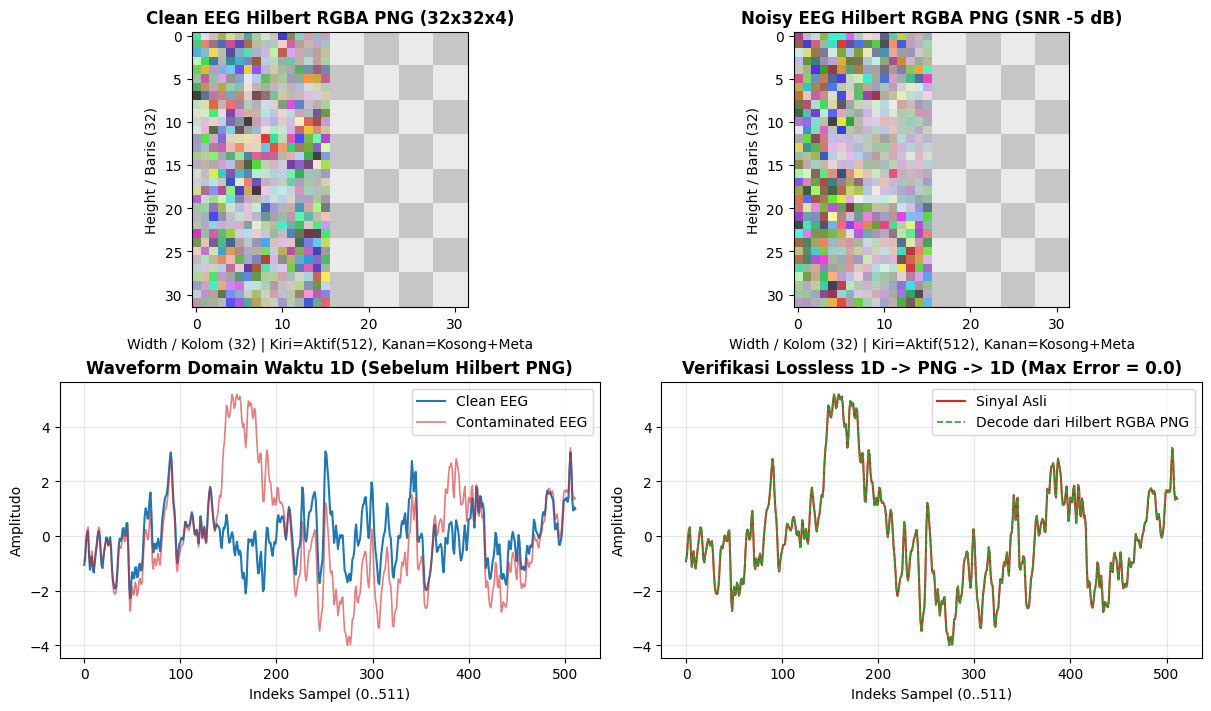

In [5]:
# ==============================================================================
# 5. PREPROCESSING: 1D WAVEFORM -> HILBERT RGBA PNG (32x32x4, 100% LOSSLESS)
# ==============================================================================
import io
import time
from functools import lru_cache

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

IMG_SIZE = 32
MAX_HILBERT_CAP = IMG_SIZE * IMG_SIZE - 1  # 1023 sampel maksimal pada grid 32x32
assert SIGNAL_LENGTH <= MAX_HILBERT_CAP, f"Panjang sinyal {SIGNAL_LENGTH} melebihi kapasitas {MAX_HILBERT_CAP}!"

try:
    from hilbert_png_codec import (
        decode_hilbert_png,
        encode_hilbert_png,
        hilbert_grid_to_rgba_array,
        hilbert_indices,
        rgba_array_to_hilbert_grid,
        rgba_array_to_signal,
        signal_to_rgba_array,
    )
    print("Codec Hilbert RGBA PNG diimpor dari hilbert_png_codec.py")
except ImportError:
    def _rot(n, x, y, rx, ry):
        if ry == 0:
            if rx == 1:
                x = n - 1 - x
                y = n - 1 - y
            x, y = y, x
        return x, y

    def _d2xy(n, d):
        t, x, y, s = d, 0, 0, 1
        while s < n:
            rx = 1 & (t // 2)
            ry = 1 & (t ^ rx)
            x, y = _rot(s, x, y, rx, ry)
            x += s * rx
            y += s * ry
            t //= 4
            s *= 2
        return x, y

    @lru_cache(maxsize=8)
    def hilbert_indices(img_size=32):
        if img_size <= 0 or (img_size & (img_size - 1)) != 0:
            raise ValueError(f"img_size harus pangkat 2 positif, bukan {img_size}.")
        coords = [_d2xy(img_size, d) for d in range(img_size * img_size)]
        xs, ys = zip(*coords)
        return np.asarray(ys, dtype=np.int64), np.asarray(xs, dtype=np.int64)

    def signal_to_rgba_array(signal, img_size=32):
        sig = np.ascontiguousarray(signal, dtype="<f4").reshape(-1)
        n = sig.size
        max_cap = img_size * img_size - 1
        if n == 0 or n > max_cap:
            raise ValueError(f"Panjang sinyal {n} harus berada di rentang [1, {max_cap}].")
        rows, cols = hilbert_indices(img_size)
        rgba = np.zeros((img_size, img_size, 4), dtype=np.uint8)
        rgba[rows[:n], cols[:n]] = sig.view(np.uint8).reshape(n, 4)
        rgba[rows[-1], cols[-1]] = np.array([n], dtype="<u4").view(np.uint8)
        return rgba

    def rgba_array_to_signal(rgba):
        if rgba.ndim != 3 or rgba.shape[2] != 4 or rgba.shape[0] != rgba.shape[1]:
            raise ValueError(f"Bentuk array RGBA tidak valid: {rgba.shape}")
        img_size = rgba.shape[0]
        rows, cols = hilbert_indices(img_size)
        n = int(np.ascontiguousarray(rgba[rows[-1], cols[-1]]).view("<u4")[0])
        max_cap = img_size * img_size - 1
        if n <= 0 or n > max_cap:
            raise ValueError(f"Metadata panjang sinyal tidak valid di piksel Hilbert terakhir: {n}")
        sig_bytes = np.ascontiguousarray(rgba[rows[:n], cols[:n]])
        return sig_bytes.view("<f4").reshape(n)

    def rgba_array_to_hilbert_grid(rgba):
        img_size = rgba.shape[0]
        rows, cols = hilbert_indices(img_size)
        sig = rgba_array_to_signal(rgba)
        n = sig.size
        grid = np.zeros((2, img_size, img_size), dtype=np.float32)
        grid[0, rows[:n], cols[:n]] = sig
        grid[1, rows[:n], cols[:n]] = 1.0
        return grid, n

    def hilbert_grid_to_rgba_array(grid, n, img_size=32):
        plane = grid[0] if grid.ndim == 3 else grid
        rows, cols = hilbert_indices(img_size)
        sig = np.ascontiguousarray(plane[rows[:n], cols[:n]], dtype="<f4")
        return signal_to_rgba_array(sig, img_size=img_size)

    def encode_hilbert_png(signal, target, img_size=32):
        rgba = signal_to_rgba_array(signal, img_size=img_size)
        Image.fromarray(rgba).save(target, format="PNG")  # mode RGBA terdeteksi otomatis dari shape (H,W,4)
        if isinstance(target, io.BytesIO):
            target.seek(0)
        return rgba.shape

    def decode_hilbert_png(source):
        if isinstance(source, io.BytesIO):
            source.seek(0)
        with Image.open(source) as img:
            rgba = np.asarray(img, dtype=np.uint8)
        return rgba_array_to_signal(rgba)
    print("Codec Hilbert RGBA PNG diinisialisasi secara standalone.")

HILBERT_ROWS_32, HILBERT_COLS_32 = hilbert_indices(IMG_SIZE)
HILBERT_ROWS_8, HILBERT_COLS_8 = hilbert_indices(8)

ROWS_32_T = torch.tensor(HILBERT_ROWS_32, dtype=torch.long, device=device)
COLS_32_T = torch.tensor(HILBERT_COLS_32, dtype=torch.long, device=device)
ROWS_ACT_T = ROWS_32_T[:SIGNAL_LENGTH]
COLS_ACT_T = COLS_32_T[:SIGNAL_LENGTH]


def signal_to_image(signal, target=None, img_size=IMG_SIZE):
    """Mengubah sinyal 1D float32 menjadi Hilbert RGBA PNG (32x32x4 uint8) dan menyimpan/mengembalikan array RGBA."""
    rgba = signal_to_rgba_array(signal, img_size=img_size)
    if target is not None:
        Image.fromarray(rgba).save(target, format="PNG")
        if isinstance(target, io.BytesIO):
            target.seek(0)
    return rgba


def image_to_signal(source):
    """Membaca file/buffer Hilbert RGBA PNG atau array RGBA uint8 kembali ke sinyal 1D float32."""
    if isinstance(source, np.ndarray):
        return rgba_array_to_signal(source)
    return decode_hilbert_png(source)


def image_tensor(waveforms, n_active=SIGNAL_LENGTH):
    """Pemetaan tensor sinyal 1D -> tensor grid Hilbert 2-channel (B, 2, 32, 32) untuk GPU training."""
    if isinstance(waveforms, torch.Tensor):
        w = waveforms.to(device=device, dtype=torch.float32)
        if w.ndim == 1:
            w = w.unsqueeze(0)
        B, n = w.shape
        grid = torch.zeros(B, 2, IMG_SIZE, IMG_SIZE, device=device, dtype=torch.float32)
        grid[:, 0, ROWS_32_T[:n], COLS_32_T[:n]] = w
        grid[:, 1, ROWS_32_T[:n], COLS_32_T[:n]] = 1.0
        return grid
    arr = np.asarray(waveforms, dtype=np.float32)
    if arr.ndim == 1:
        arr = arr[None, :]
    B, n = arr.shape
    grids = np.zeros((B, 2, IMG_SIZE, IMG_SIZE), dtype=np.float32)
    grids[:, 0, HILBERT_ROWS_32[:n], HILBERT_COLS_32[:n]] = arr
    grids[:, 1, HILBERT_ROWS_32[:n], HILBERT_COLS_32[:n]] = 1.0
    return torch.from_numpy(grids).to(device=device, dtype=torch.float32)


def batch_via_hilbert_png_to_grid(waveforms_np, img_size=IMG_SIZE):
    """Melakukan konversi nyata: sinyal -> encode PNG di memori -> parse PNG -> tensor grid (B, 2, 32, 32)."""
    arr = np.asarray(waveforms_np, dtype=np.float32)
    if arr.ndim == 1:
        arr = arr[None, :]
    B = len(arr)
    grids = np.empty((B, 2, img_size, img_size), dtype=np.float32)
    lengths = np.empty(B, dtype=np.int64)
    for i in range(B):
        buf = io.BytesIO()
        encode_hilbert_png(arr[i], buf, img_size=img_size)
        with Image.open(buf) as img:
            rgba = np.asarray(img, dtype=np.uint8)
        grids[i], lengths[i] = rgba_array_to_hilbert_grid(rgba)
    return grids, lengths


def grid_to_signal(pred_grid, n_active=SIGNAL_LENGTH):
    """Mengekstrak sinyal 1D sepanjang kurva Hilbert dari output tensor model (B, 1, 32, 32)."""
    if isinstance(pred_grid, torch.Tensor):
        return pred_grid[:, 0, ROWS_32_T[:n_active], COLS_32_T[:n_active]]
    return pred_grid[..., HILBERT_ROWS_32[:n_active], HILBERT_COLS_32[:n_active]]


def rgba_on_checkerboard(rgba, tile=4):
    """Helper visualisasi RGBA PNG di atas latar papan catur agar kanal alpha terlihat jelas."""
    h, w, _ = rgba.shape
    yy, xx = np.indices((h, w))
    bg = np.where(((yy // tile + xx // tile) % 2) == 0, 0.92, 0.78)[..., None]
    rgb = rgba[..., :3].astype(np.float32) / 255.0
    alpha = rgba[..., 3:4].astype(np.float32) / 255.0
    return np.clip(rgb * alpha + bg * (1.0 - alpha), 0.0, 1.0)


# ------------------------------------------------------------------------------
# Verifikasi lossless invertibility melalui Hilbert RGBA PNG fisik (buffer PNG)
# ------------------------------------------------------------------------------
SNR_PLOT, IDX = -5, 0
clean_sample = clean_train[IDX].astype(np.float32)
noisy_sample = contaminated_train[SNR_PLOT][IDX].astype(np.float32)

clean_png_buf = io.BytesIO()
noisy_png_buf = io.BytesIO()
shape_clean = encode_hilbert_png(clean_sample, clean_png_buf, img_size=IMG_SIZE)
shape_noisy = encode_hilbert_png(noisy_sample, noisy_png_buf, img_size=IMG_SIZE)

clean_rgba = np.asarray(Image.open(clean_png_buf), dtype=np.uint8)
noisy_rgba = np.asarray(Image.open(noisy_png_buf), dtype=np.uint8)
roundtrip_noisy = decode_hilbert_png(noisy_png_buf)

# Verifikasi panjang dinamis (contoh 300 sampel) dalam dimensi PNG tetap 32x32x4
dyn_sig = noisy_sample[:300]
dyn_buf = io.BytesIO()
shape_dyn = encode_hilbert_png(dyn_sig, dyn_buf, img_size=IMG_SIZE)
roundtrip_dyn = decode_hilbert_png(dyn_buf)

# Verifikasi kesetaraan eksak antara grid hasil decode PNG vs tensor GPU cepat
grid_from_png, decoded_len = rgba_array_to_hilbert_grid(noisy_rgba)
grid_from_gpu = image_tensor(noisy_sample[None])[0].cpu().numpy()
png_vs_gpu_diff = float(np.max(np.abs(grid_from_png - grid_from_gpu)))

max_roundtrip_err = float(np.max(np.abs(roundtrip_noisy - noisy_sample)))
max_dyn_err = float(np.max(np.abs(roundtrip_dyn - dyn_sig)))
print(f"Dimensi Sinyal      : {SIGNAL_LENGTH} sampel -> Hilbert RGBA PNG {shape_noisy} (kapasitas maks {MAX_HILBERT_CAP})")
print(f"Ukuran File PNG     : clean={len(clean_png_buf.getvalue()):,} B | noisy={len(noisy_png_buf.getvalue()):,} B")
print(f"Metadata Piksel Last: {noisy_rgba[HILBERT_ROWS_32[-1], HILBERT_COLS_32[-1]].tolist()} -> N={decoded_len}")
print(f"Round-trip Error 512: max |error| = {max_roundtrip_err:.10g} (Exact equality: {np.array_equal(roundtrip_noisy, noisy_sample)})")
print(f"Round-trip Error 300: shape={shape_dyn}, len={len(roundtrip_dyn)}, max |error| = {max_dyn_err:.10g} (Exact equality: {np.array_equal(roundtrip_dyn, dyn_sig)})")
print(f"PNG Grid vs GPU Grid: max |diff| = {png_vs_gpu_diff:.10g}")
assert max_roundtrip_err == 0.0 and max_dyn_err == 0.0 and png_vs_gpu_diff == 0.0

# ------------------------------------------------------------------------------
# Encode/decode set validasi nyata melalui Hilbert RGBA PNG
# ------------------------------------------------------------------------------
t_val_png = time.perf_counter()
X_val_grids_np, _ = batch_via_hilbert_png_to_grid(X_val.cpu().numpy(), img_size=IMG_SIZE)
X_val_img = torch.from_numpy(X_val_grids_np).to(device=device, dtype=torch.float32)
Y_val_img = image_tensor(Y_val)
print(f"Tensor citra validasi (dari RGBA PNG): {tuple(X_val_img.shape)} | dtype: {X_val_img.dtype} ({time.perf_counter()-t_val_png:.2f}s)")

# ------------------------------------------------------------------------------
# RMSE konversi: sinyal -> image  dan  image -> sinyal
# ------------------------------------------------------------------------------
def rmse(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    return float(np.sqrt(np.mean((a - b) ** 2)))


def conversion_rmse(sig_orig, name):
    """sig_orig: sinyal asli (dtype asli, mis. float64) -> dievaluasi lewat PNG fisik."""
    sig32 = np.asarray(sig_orig).astype(np.float32)

    # sinyal -> PNG -> array RGBA
    buf = io.BytesIO()
    encode_hilbert_png(sig32, buf, img_size=IMG_SIZE)
    rgba = np.asarray(Image.open(buf), dtype=np.uint8)

    # (A) SINYAL -> IMAGE: grid dari PNG vs grid referensi yang dibangun langsung dari sinyal
    grid_png, n = rgba_array_to_hilbert_grid(rgba)                 # (2, 32, 32)
    grid_ref = image_tensor(sig32[None])[0].cpu().numpy()          # (2, 32, 32)
    mask = grid_ref[1] > 0
    r_s2i_active = rmse(grid_png[0][mask], grid_ref[0][mask])      # piksel aktif saja
    r_s2i_full = rmse(grid_png[0], grid_ref[0])                    # seluruh 1024 piksel

    # (B) IMAGE -> SINYAL: sinyal hasil decode vs sinyal asli
    sig_back = decode_hilbert_png(buf)
    r_i2s_f32 = rmse(sig_back, sig32)                              # murni codec (vs float32)
    r_i2s_orig = rmse(sig_back, sig_orig)                          # vs dtype asli (termasuk cast ke float32)

    print(f"[{name}] N={n}")
    print(f"  Sinyal -> Image  (piksel aktif)         : {r_s2i_active:.3e}")
    print(f"  Sinyal -> Image  (seluruh grid 1024)    : {r_s2i_full:.3e}")
    print(f"  Image  -> Sinyal (vs float32)           : {r_i2s_f32:.3e}")
    print(f"  Image  -> Sinyal (vs dtype asli {np.asarray(sig_orig).dtype}) : {r_i2s_orig:.3e}")
    return r_s2i_active, r_i2s_f32, r_i2s_orig


print("=" * 70)
conversion_rmse(clean_train[IDX], "Clean")
conversion_rmse(contaminated_train[SNR_PLOT][IDX], f"Noisy SNR {SNR_PLOT} dB")
print("=" * 70)

# Seluruh set validasi (memakai grid dari PNG fisik yang dibuat di atas)
with torch.no_grad():
    X_ref_img = image_tensor(X_val)                                # grid langsung dari sinyal
    mask_val = X_ref_img[:, 1:2]
    d = (X_val_img[:, 0:1] - X_ref_img[:, 0:1]) * mask_val
    rmse_s2i = torch.sqrt(d.pow(2).sum(dim=(1, 2, 3)) / mask_val.sum(dim=(1, 2, 3)))

    X_back = grid_to_signal(X_val_img, SIGNAL_LENGTH)              # image -> sinyal
    rmse_i2s = torch.sqrt(((X_back - X_val.to(device=device, dtype=torch.float32)) ** 2).mean(dim=1))

print(f"[Validasi] RMSE Sinyal -> Image : mean={rmse_s2i.mean():.3e} | max={rmse_s2i.max():.3e}")
print(f"[Validasi] RMSE Image -> Sinyal : mean={rmse_i2s.mean():.3e} | max={rmse_i2s.max():.3e}")

# ------------------------------------------------------------------------------
# Visualisasi perbandingan Hilbert RGBA PNG 2D dan Sinyal 1D
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for ax, rgba_im, title in [
    (axes[0, 0], clean_rgba, f"Clean EEG Hilbert RGBA PNG ({IMG_SIZE}x{IMG_SIZE}x4)"),
    (axes[0, 1], noisy_rgba, f"Noisy EEG Hilbert RGBA PNG (SNR {SNR_PLOT} dB)"),
]:
    ax.imshow(rgba_on_checkerboard(rgba_im), interpolation="nearest")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Width / Kolom (32) | Kiri=Aktif(512), Kanan=Kosong+Meta")
    ax.set_ylabel("Height / Baris (32)")

axes[1, 0].plot(clean_sample, label="Clean EEG", color="#1f77b4", lw=1.5)
axes[1, 0].plot(noisy_sample, label="Contaminated EEG", color="#d62728", alpha=0.6, lw=1.2)
axes[1, 0].set_title("Waveform Domain Waktu 1D (Sebelum Hilbert PNG)", fontweight="bold")
axes[1, 0].set_xlabel("Indeks Sampel (0..511)")
axes[1, 0].set_ylabel("Amplitudo")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(noisy_sample, label="Sinyal Asli", color="#d62728", lw=1.5)
axes[1, 1].plot(roundtrip_noisy, "--", label="Decode dari Hilbert RGBA PNG", color="#2ca02c", lw=1.2)
axes[1, 1].set_title(f"Verifikasi Lossless 1D -> PNG -> 1D (Max Error = {max_roundtrip_err})", fontweight="bold")
axes[1, 1].set_xlabel("Indeks Sampel (0..511)")
axes[1, 1].set_ylabel("Amplitudo")
axes[1, 1].grid(alpha=0.3)
axes[1, 1].legend()
plt.show()

In [6]:
# ==============================================================================
# 6. ARSITEKTUR MODEL USULAN: Hilbert-ResUNet2D
# ==============================================================================
class SEBlock2D(nn.Module):
    """Squeeze-and-Excitation Channel Attention 2D."""
    def __init__(self, ch, reduction=4):
        super().__init__()
        mid = max(4, ch // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, mid, 1),
            nn.GELU(),
            nn.Conv2d(mid, ch, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(x)


class ResBlock2D(nn.Module):
    """Residual Block 2D dengan GroupNorm, GELU, dan SE Attention pada grid Hilbert."""
    def __init__(self, in_ch, out_ch, k=3):
        super().__init__()
        g = min(8, out_ch)
        pad = k // 2
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=k, padding=pad, bias=False)
        self.gn1 = nn.GroupNorm(g, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=k, padding=pad, bias=False)
        self.gn2 = nn.GroupNorm(g, out_ch)
        self.se = SEBlock2D(out_ch)
        self.act = nn.GELU()
        self.shortcut = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1, bias=False)

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.se(self.gn2(self.conv2(out)))
        return self.act(out + res)


class HilbertSpectralGate1D(nn.Module):
    """
    Gerbang Spektral rFFT Paralel sepanjang jalur kurva Hilbert:
    Mengekstrak sinyal fitur sesuai urutan kronologis kurva Hilbert (termasuk panjang dinamis
    via active_mask), menyaring artefak EOG di domain Fourier, lalu mengembalikannya ke grid 2D.
    """
    def __init__(self, rows_32, cols_32, n_seq=1024, channels=16):
        super().__init__()
        self.register_buffer("rows_h", torch.tensor(rows_32[:n_seq], dtype=torch.long))
        self.register_buffer("cols_h", torch.tensor(cols_32[:n_seq], dtype=torch.long))
        self.n_seq = n_seq
        n_freqs = n_seq // 2 + 1
        self.net = nn.Sequential(
            nn.Conv1d(channels * 2, channels * 2, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv1d(channels * 2, channels * 2, kernel_size=1),
        )
        self.freq_scale = nn.Parameter(torch.ones(1, channels, n_freqs))

    def forward(self, x_2d, mask_2d):
        sig = x_2d[:, :, self.rows_h, self.cols_h] * mask_2d[:, :, self.rows_h, self.cols_h]
        spec = torch.fft.rfft(sig, dim=-1, norm="ortho")
        cat = torch.cat([spec.real, spec.imag], dim=1)
        dr, di = torch.chunk(self.net(cat), 2, dim=1)
        spec_out = torch.complex(spec.real * self.freq_scale + dr, spec.imag * self.freq_scale + di)
        filtered = torch.fft.irfft(spec_out, n=self.n_seq, dim=-1, norm="ortho")
        out = torch.zeros_like(x_2d)
        out[:, :, self.rows_h, self.cols_h] = filtered * mask_2d[:, :, self.rows_h, self.cols_h]
        return out


class HilbertResUNet2D(nn.Module):
    """
    [OUR PROPOSED MODEL]
    Hilbert RGBA PNG 2D ResUNet with Chronological Hilbert BiLSTM-Transformer & Spectral Gate
    Input  : (B, 2, 32, 32) -> [signal, active_mask] hasil decode Hilbert RGBA PNG
    Output : (B, 1, 32, 32) -> prediksi grid Hilbert bersih (siap dikemas kembali ke RGBA PNG)
    """
    def __init__(self, base=16, lstm_layers=2, attn_heads=4, dropout=0.1, img_size=32):
        super().__init__()
        ch1, ch2, ch3, ch4 = base, base * 2, base * 4, base * 8  # 16, 32, 64, 128

        r32, c32 = hilbert_indices(img_size)
        r8, c8 = hilbert_indices(img_size // 4)
        self.register_buffer("rows8", torch.tensor(r8, dtype=torch.long))
        self.register_buffer("cols8", torch.tensor(c8, dtype=torch.long))

        # Dual-scale 2D Stem (lokal 3x3 + luas 5x5) menerima 2 kanal: [signal, active_mask]
        self.stem_local = nn.Conv2d(2, ch1 // 2, kernel_size=3, padding=1, bias=False)
        self.stem_wide = nn.Conv2d(2, ch1 // 2, kernel_size=5, padding=2, bias=False)
        self.stem_gn = nn.GroupNorm(min(8, ch1), ch1)
        self.stem_act = nn.GELU()

        # Encoder isotropik (2, 2) yang menjaga lokalitas blok kurva Hilbert
        self.enc1 = ResBlock2D(ch1, ch1, k=3)                 # (B, 16, 32, 32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)    # -> (16, 16)

        self.enc2 = ResBlock2D(ch1, ch2, k=3)                 # (B, 32, 16, 16)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)    # -> (8, 8)

        self.enc3 = ResBlock2D(ch2, ch3, k=3)                 # (B, 64, 8, 8)

        # Bottleneck: (B, 128, 8, 8) -> 64 token kronologis diurutkan via hilbert_indices(8)
        self.bottleneck_conv = ResBlock2D(ch3, ch4, k=3)
        self.bilstm = nn.LSTM(
            ch4, ch4 // 2, num_layers=lstm_layers,
            batch_first=True, bidirectional=True, dropout=dropout if lstm_layers > 1 else 0.0
        )
        n_tokens = (img_size // 4) ** 2
        self.pos_emb = nn.Parameter(torch.zeros(1, n_tokens, ch4))
        nn.init.trunc_normal_(self.pos_emb, std=0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=ch4, nhead=attn_heads, dim_feedforward=ch4 * 2,
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=1, norm=nn.LayerNorm(ch4), enable_nested_tensor=False
        )

        # Decoder + Skip Connections
        self.dec3 = ResBlock2D(ch4 + ch3, ch3, k=3)
        self.up2 = nn.ConvTranspose2d(ch3, ch2, kernel_size=2, stride=2)  # -> (16, 16)
        self.dec2 = ResBlock2D(ch2 + ch2, ch2, k=3)
        self.up1 = nn.ConvTranspose2d(ch2, ch1, kernel_size=2, stride=2)  # -> (32, 32)
        self.dec1 = ResBlock2D(ch1 + ch1, ch1, k=3)

        # Dual-Domain Hilbert Spectral Fusion & Projection Head
        self.spec_gate = HilbertSpectralGate1D(r32, c32, n_seq=img_size * img_size, channels=ch1)
        self.final_fuse = ResBlock2D(ch1 * 2, ch1, k=3)
        self.final_head = nn.Conv2d(ch1, 1, kernel_size=1)

    def forward(self, x):
        # Masked Reversible Instance Normalization (Masked RevIN) hanya pada piksel aktif
        sig = x[:, 0:1]
        mask = x[:, 1:2]
        cnt = mask.sum(dim=(-2, -1), keepdim=True).clamp_min(1.0)
        mu = (sig * mask).sum(dim=(-2, -1), keepdim=True) / cnt
        var = (((sig - mu) * mask) ** 2).sum(dim=(-2, -1), keepdim=True) / cnt
        sd = torch.sqrt(var + 1e-6)
        sig_norm = ((sig - mu) / sd) * mask
        xn = torch.cat([sig_norm, mask], dim=1)

        s = self.stem_act(self.stem_gn(torch.cat([self.stem_local(xn), self.stem_wide(xn)], dim=1)))

        e1 = self.enc1(s)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))

        b = self.bottleneck_conv(e3)
        seq = b[:, :, self.rows8, self.cols8].transpose(1, 2)  # (B, 64, 128) kronologis Hilbert
        lstm_out, _ = self.bilstm(seq)
        seq = seq + lstm_out
        seq = seq + self.transformer(seq + self.pos_emb)
        b_seq = b.clone()
        b_seq[:, :, self.rows8, self.cols8] = seq.transpose(1, 2)

        d3 = self.dec3(torch.cat([b_seq, e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        d_spec = self.spec_gate(d1, mask)
        d_fused = self.final_fuse(torch.cat([d1, d_spec], dim=1))
        out_norm = sig_norm + self.final_head(d_fused)

        return (out_norm * sd + mu) * mask

model = HilbertResUNet2D(base=16, lstm_layers=2, attn_heads=4, dropout=0.1, img_size=IMG_SIZE).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
model_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
print(f"Model: Our Proposed Hilbert-ResUNet2D (Hilbert RGBA PNG {IMG_SIZE}x{IMG_SIZE}x4)")
print(f"Trainable parameters: {n_params:,} | Ukuran model (FP32): {model_bytes/1024:.2f} KB")


Model: Our Proposed Hilbert-ResUNet2D (Hilbert RGBA PNG 32x32x4)
Trainable parameters: 888,413 | Ukuran model (FP32): 3470.36 KB


In [7]:
# ==============================================================================
# 7. MULTI-DOMAIN LOSS FUNCTION & OPTIMIZER CONFIGURATION
# ==============================================================================
LAMBDA_CC = 3.5
LAMBDA_SPEC = 0.25

def criterion(pred, target):
    """
    Multi-Domain Composite Loss pada sampel aktif kurva Hilbert:
    1. Scale-normalized L1 Loss (amplitudo waktu).
    2. Pearson Correlation Loss (morfologi bentuk gelombang EEG).
    3. Spectral Magnitude Loss (spektrum daya FFT frekuensi).
    """
    p = grid_to_signal(pred, n_active=SIGNAL_LENGTH)
    t = grid_to_signal(target, n_active=SIGNAL_LENGTH) if target.ndim == 4 else target.reshape(target.shape[0], -1)

    t_std = t.std(dim=-1, keepdim=True) + 1e-6
    l1 = F.l1_loss(p / t_std, t / t_std)

    pm = p - p.mean(dim=-1, keepdim=True)
    tm = t - t.mean(dim=-1, keepdim=True)
    cc = (pm * tm).sum(dim=-1) / (torch.sqrt(pm.pow(2).sum(dim=-1) * tm.pow(2).sum(dim=-1)) + 1e-8)
    loss_cc = 1.0 - cc.mean()

    pf = torch.abs(torch.fft.rfft(p, dim=-1, norm="ortho"))
    tf = torch.abs(torch.fft.rfft(t, dim=-1, norm="ortho"))
    loss_spec = F.l1_loss(pf, tf)

    return l1 + LAMBDA_CC * loss_cc + LAMBDA_SPEC * loss_spec

LEARNING_RATE = 1.2e-3
MAX_EPOCHS = 150
MAX_GRAD_NORM = 1.0
BATCH_SIZE = 256

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-5)

class EarlyStopping:
    def __init__(self, patience=30, min_delta=1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        val_loss = float(val_loss)
        if not math.isfinite(val_loss):
            self.stop = True
            return self.stop
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return self.stop

    def restore_best_weights(self, model):
        if self.best_state is None:
            raise RuntimeError("No valid checkpoint saved.")
        model.load_state_dict(self.best_state)

early_stopping = EarlyStopping(patience=30, min_delta=1e-5)


In [8]:
# ==============================================================================
# 8. TRAINING LOOP DENGAN DYNAMIC CROSS-PAIRING & EARLY STOPPING
# ==============================================================================
history = {"train_loss": [], "val_loss": [], "lr": []}
t_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    t_ep = time.time()
    X_ep, Y_ep = build_epoch_gpu(cross_pair_prob=0.75, alpha_jitter=0.20, do_shift=True)
    Xt = image_tensor(X_ep)
    Yt = image_tensor(Y_ep)

    model.train()
    train_running = 0.0
    for i in range(0, len(Xt), BATCH_SIZE):
        xb = Xt[i:i+BATCH_SIZE]
        yb = Yt[i:i+BATCH_SIZE]
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        optimizer.step()
        train_running += loss.item() * len(xb)
    epoch_train_loss = train_running / len(Xt)

    model.eval()
    with torch.no_grad():
        val_total = 0.0
        for i in range(0, len(X_val_img), 1024):
            xb, yb = X_val_img[i:i+1024], Y_val_img[i:i+1024]
            val_total += criterion(model(xb), yb).item() * len(xb)
        epoch_val_loss = val_total / len(X_val_img)

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["lr"].append(current_lr)

    print(f"Epoch {epoch:03d}/{MAX_EPOCHS} | Train {epoch_train_loss:.6f} | Val {epoch_val_loss:.6f} | LR {current_lr:.2e} | {time.time()-t_ep:.2f}s", flush=True)

    if early_stopping(epoch_val_loss, model):
        print(f"Early stopping pada epoch {epoch}")
        break

train_wall_sec = time.time() - t_start
print(f"Training selesai dalam {train_wall_sec/60:.2f} menit")
early_stopping.restore_best_weights(model)
print(f"Best Val Loss: {early_stopping.best_loss:.6f}")


Epoch 001/150 | Train 1.075338 | Val 0.755847 | LR 1.20e-03 | 25.00s
Epoch 002/150 | Train 0.752720 | Val 0.673048 | LR 1.20e-03 | 11.49s
Epoch 003/150 | Train 0.685499 | Val 0.651106 | LR 1.20e-03 | 11.70s
Epoch 004/150 | Train 0.656647 | Val 0.596687 | LR 1.20e-03 | 11.96s
Epoch 005/150 | Train 0.641988 | Val 0.592992 | LR 1.20e-03 | 12.08s
Epoch 006/150 | Train 0.629297 | Val 0.561487 | LR 1.20e-03 | 12.34s
Epoch 007/150 | Train 0.612443 | Val 0.571208 | LR 1.20e-03 | 12.56s
Epoch 008/150 | Train 0.611647 | Val 0.560105 | LR 1.19e-03 | 12.47s
Epoch 009/150 | Train 0.597147 | Val 0.558260 | LR 1.19e-03 | 12.26s
Epoch 010/150 | Train 0.595539 | Val 0.567273 | LR 1.19e-03 | 12.19s
Epoch 011/150 | Train 0.588057 | Val 0.544622 | LR 1.19e-03 | 12.19s
Epoch 012/150 | Train 0.586509 | Val 0.553348 | LR 1.18e-03 | 12.22s
Epoch 013/150 | Train 0.581679 | Val 0.533817 | LR 1.18e-03 | 12.31s
Epoch 014/150 | Train 0.573966 | Val 0.544433 | LR 1.18e-03 | 12.33s
Epoch 015/150 | Train 0.570152 | V

Input RGBA PNG bytes  : 2,117 bytes | Output RGBA PNG bytes: 2,140 bytes
CC Noisy vs Clean     : 0.4711
CC Denoised vs Clean  : 0.9832


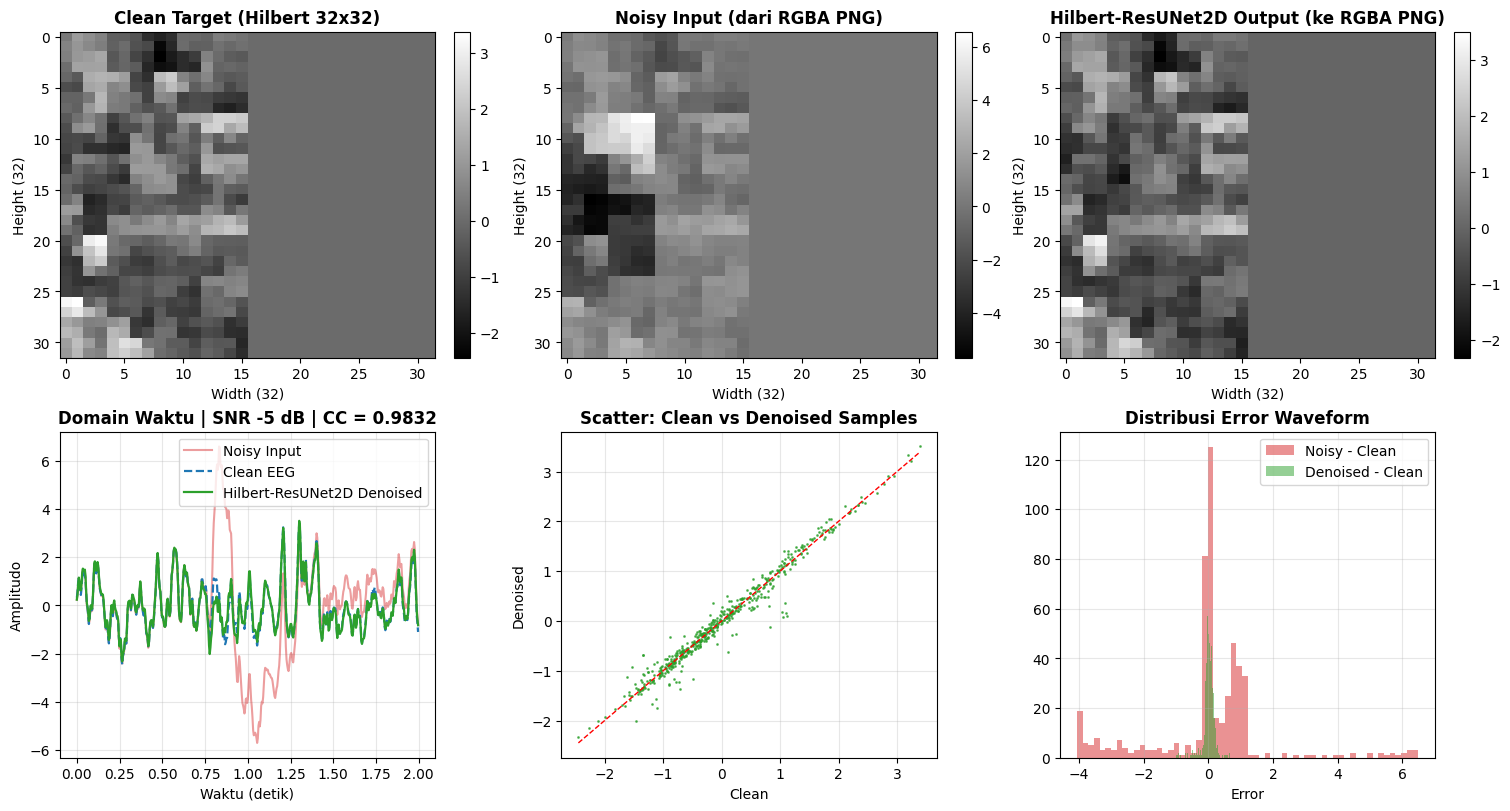

In [9]:
# ==============================================================================
# 9. VISUALISASI HASIL DENOISING SAMPEL UJI (HILBERT RGBA PNG & WAVEFORM 1D)
# ==============================================================================
SNR_PLOT, IDX = -5, 0

clean = clean_test[IDX].astype(np.float32)
noisy = contaminated_test[SNR_PLOT][IDX].astype(np.float32)

# Jalur End-to-End Hilbert RGBA PNG: sinyal -> PNG -> model -> PNG -> sinyal
in_png_buf = io.BytesIO()
out_png_buf = io.BytesIO()
encode_hilbert_png(noisy, in_png_buf, img_size=IMG_SIZE)
with Image.open(in_png_buf) as im_in:
    rgba_in_sample = np.asarray(im_in, dtype=np.uint8)
grid_in_sample, n_sample = rgba_array_to_hilbert_grid(rgba_in_sample)

model.eval()
with torch.no_grad():
    pred_grid_sample = model(torch.from_numpy(grid_in_sample).unsqueeze(0).to(device)).squeeze(0).cpu().numpy()

rgba_out_sample = hilbert_grid_to_rgba_array(pred_grid_sample, n=n_sample, img_size=IMG_SIZE)
Image.fromarray(rgba_out_sample, mode="RGBA").save(out_png_buf, format="PNG")
out_png_buf.seek(0)
den = decode_hilbert_png(out_png_buf)

clean_grid_vis = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)
clean_grid_vis[HILBERT_ROWS_32[:SIGNAL_LENGTH], HILBERT_COLS_32[:SIGNAL_LENGTH]] = clean
noisy_grid_vis = grid_in_sample[0]
den_grid_vis = pred_grid_sample[0]

cc = lambda a, b: float(np.corrcoef(a, b)[0, 1])
print(f"Input RGBA PNG bytes  : {len(in_png_buf.getvalue()):,} bytes | Output RGBA PNG bytes: {len(out_png_buf.getvalue()):,} bytes")
print(f"CC Noisy vs Clean     : {cc(clean, noisy):.4f}")
print(f"CC Denoised vs Clean  : {cc(clean, den):.4f}")

t = np.arange(SIGNAL_LENGTH) / FS
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)

for ax, img, title in zip(
    axes[0],
    [clean_grid_vis, noisy_grid_vis, den_grid_vis],
    ["Clean Target (Hilbert 32x32)", "Noisy Input (dari RGBA PNG)", "Hilbert-ResUNet2D Output (ke RGBA PNG)"],
):
    im = ax.imshow(img, cmap="gray", interpolation="nearest", aspect="auto")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Width (32)")
    ax.set_ylabel("Height (32)")
    fig.colorbar(im, ax=ax)

axes[1, 0].plot(t, noisy, color="#d62728", alpha=0.45, label="Noisy Input")
axes[1, 0].plot(t, clean, color="#1f77b4", lw=1.6, ls="--", label="Clean EEG")
axes[1, 0].plot(t, den, color="#2ca02c", lw=1.6, label="Hilbert-ResUNet2D Denoised")
axes[1, 0].set_title(f"Domain Waktu | SNR {SNR_PLOT} dB | CC = {cc(clean, den):.4f}", fontweight="bold")
axes[1, 0].set_xlabel("Waktu (detik)")
axes[1, 0].set_ylabel("Amplitudo")
axes[1, 0].grid(alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(clean, den, ".", markersize=2, color="#2ca02c", alpha=0.7)
axes[1, 1].plot([clean.min(), clean.max()], [clean.min(), clean.max()], "r--", lw=1)
axes[1, 1].set_title("Scatter: Clean vs Denoised Samples", fontweight="bold")
axes[1, 1].set_xlabel("Clean")
axes[1, 1].set_ylabel("Denoised")
axes[1, 1].grid(alpha=0.3)

axes[1, 2].hist(noisy - clean, bins=60, alpha=0.5, color="#d62728", label="Noisy - Clean")
axes[1, 2].hist(den - clean, bins=60, alpha=0.5, color="#2ca02c", label="Denoised - Clean")
axes[1, 2].set_title("Distribusi Error Waveform", fontweight="bold")
axes[1, 2].set_xlabel("Error")
axes[1, 2].grid(alpha=0.3)
axes[1, 2].legend()

plt.show()


In [10]:
# ==============================================================================
# 10. EVALUASI LENGKAP PADA TEST SET DI SELURUH LEVEL SNR (-7 dB s/d +2 dB)
# ==============================================================================
def calc_cc_per_epoch(clean, pred):
    c = clean - clean.mean(-1, keepdims=True)
    p = pred - pred.mean(-1, keepdims=True)
    return np.sum(c * p, -1) / (np.sqrt(np.sum(c**2, -1) * np.sum(p**2, -1)) + 1e-8)

def cc_mean(clean, pred):
    return float(calc_cc_per_epoch(clean, pred).mean())

def rrmse_temporal(clean, pred):
    num = np.sqrt(np.mean((clean - pred)**2, -1))
    den = np.sqrt(np.mean(clean**2, -1))
    return float(np.mean(num / (den + 1e-8)))

def rrmse_spectral(clean, pred):
    cf = np.abs(np.fft.rfft(clean, axis=-1))
    pf = np.abs(np.fft.rfft(pred, axis=-1))
    num = np.sqrt(np.mean((cf - pf)**2, -1))
    den = np.sqrt(np.mean(cf**2, -1))
    return float(np.mean(num / (den + 1e-8)))

def snr_out_db(clean, pred):
    err = clean - pred
    return float(10 * np.log10(np.mean(clean**2) / (np.mean(err**2) + 1e-20)))

def snr_in_db(clean, noisy):
    err = noisy - clean
    return float(10 * np.log10(np.mean(clean**2) / (np.mean(err**2) + 1e-20)))

def spec_err_db(clean, pred):
    cf = np.abs(np.fft.rfft(clean, axis=-1))
    pf = np.abs(np.fft.rfft(pred, axis=-1))
    return float(10 * np.log10((np.mean((cf - pf)**2) + 1e-20) / (np.mean(cf**2) + 1e-20)))

def model_predict_via_png(arr, batch_size=256):
    """Inferensi end-to-end melalui encode PNG -> baca PNG -> model 2D -> simpan PNG -> decode PNG."""
    arr = np.asarray(arr, dtype=np.float32)
    n_total = len(arr)
    out_signals = np.empty_like(arr, dtype=np.float64)
    model.eval()
    with torch.no_grad():
        for i in range(0, n_total, batch_size):
            sub = arr[i:i+batch_size]
            grids_np, lengths = batch_via_hilbert_png_to_grid(sub, img_size=IMG_SIZE)
            inp = torch.from_numpy(grids_np).to(device=device, dtype=torch.float32)
            pred_grids = model(inp).cpu().numpy()
            for j in range(len(sub)):
                rgba_out = hilbert_grid_to_rgba_array(pred_grids[j], n=int(lengths[j]), img_size=IMG_SIZE)
                out_buf = io.BytesIO()
                Image.fromarray(rgba_out, mode="RGBA").save(out_buf, format="PNG")
                out_buf.seek(0)
                out_signals[i + j] = decode_hilbert_png(out_buf)
    return out_signals

def model_predict_fast(arr, batch_size=256):
    """Inferensi cepat langsung di tensor grid Hilbert untuk microbenchmark murni jaringan saraf."""
    arr = np.asarray(arr, dtype=np.float32)
    result = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(arr), batch_size):
            batch_img = image_tensor(arr[i:i+batch_size])
            pred_sig = grid_to_signal(model(batch_img), n_active=arr.shape[1]).cpu().numpy()
            result.append(pred_sig)
    return np.concatenate(result, axis=0).astype(np.float64)

model_predict = model_predict_via_png

ct = clean_test.astype(np.float64)
preds, rows = {}, []

for snr in SNR_KEYS:
    noisy = contaminated_test[snr].astype(np.float64)
    pred = model_predict(noisy)
    preds[snr] = pred
    sin = snr_in_db(ct, noisy)
    sout = snr_out_db(ct, pred)
    rows.append({
        "SNR Level (dB)": snr,
        "SNR in (dB)": sin,
        "SNR out (dB)": sout,
        "Delta SNR (dB)": sout - sin,
        "CC noisy": cc_mean(ct, noisy),
        "CC denoised": cc_mean(ct, pred),
        "RRMSE (Time)": rrmse_temporal(ct, pred),
        "RRMSE (Freq)": rrmse_spectral(ct, pred),
        "Spec err (dB)": spec_err_db(ct, pred),
    })

df_results = pd.DataFrame(rows)
print("=" * 118)
print("HASIL EVALUASI TEST SET - PER LEVEL SNR (Hilbert-ResUNet2D via Hilbert RGBA PNG)")
print("=" * 118)
print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
print(f"CC denoised mean : {df_results['CC denoised'].mean():.4f}  (noisy: {df_results['CC noisy'].mean():.4f})")
print(f"SNR out mean     : {df_results['SNR out (dB)'].mean():.2f} dB  (in: {df_results['SNR in (dB)'].mean():.2f} dB, delta: {df_results['Delta SNR (dB)'].mean():.2f} dB)")
print(f"RRMSE time/freq  : {df_results['RRMSE (Time)'].mean():.4f} / {df_results['RRMSE (Freq)'].mean():.4f}")


HASIL EVALUASI TEST SET - PER LEVEL SNR (Hilbert-ResUNet2D via Hilbert RGBA PNG)
 SNR Level (dB)  SNR in (dB)  SNR out (dB)  Delta SNR (dB)  CC noisy  CC denoised  RRMSE (Time)  RRMSE (Freq)  Spec err (dB)
             -7      -7.0000        7.7433         14.7433    0.4006       0.9134        0.3904        0.2564       -11.4178
             -6      -6.0000        8.1037         14.1037    0.4410       0.9202        0.3738        0.2490       -11.6514
             -5      -5.0000        8.3948         13.3948    0.4835       0.9254        0.3607        0.2426       -11.8557
             -4      -4.0000        8.6367         12.6367    0.5275       0.9296        0.3500        0.2364       -12.0595
             -3      -3.0000        8.8575         11.8575    0.5724       0.9331        0.3404        0.2304       -12.2600
             -2      -2.0000        9.1025         11.1025    0.6174       0.9369        0.3304        0.2242       -12.4714
             -1      -1.0000        9.3718  

In [11]:
# ==============================================================================
# 11. PERBANDINGAN TERHADAP METODE BASELINE KLASIK
# ==============================================================================
sample = contaminated_test[SNR_KEYS[0]][:min(128, len(test_idx))].astype(np.float32)
for _ in range(3):
    model_predict_fast(sample)
if device.type == "cuda":
    torch.cuda.synchronize()

N_REP = 10
t0 = time.perf_counter()
for _ in range(N_REP):
    model_predict_fast(sample)
if device.type == "cuda":
    torch.cuda.synchronize()
dur = time.perf_counter() - t0
latency_us = dur / N_REP / len(sample) * 1e6
throughput = len(sample) / (dur / N_REP)

b_hp, a_hp = butter(4, 8 / 256.0, btype="high")

nrm = lambda a: a / (np.sqrt(np.mean(a**2, axis=-1, keepdims=True)) + 1e-8)
A_tr = contaminated_train[SNR_KEYS[0]].astype(np.float64) - clean_train
tmpl = nrm(A_tr).mean(0)
tmpl = tmpl / (np.sqrt(np.mean(tmpl**2)) + 1e-8)
def tmpl_predict(x):
    c = (x @ tmpl) / (tmpl @ tmpl)
    return x - c[:, None] * tmpl[None, :]

METHODS = {
    "Noisy Input": lambda x: x,
    "Our Proposed (Hilbert PNG)": model_predict,
    "Highpass 8Hz Butterworth": lambda x: filtfilt(b_hp, a_hp, x, axis=-1),
    "Template-LS": tmpl_predict,
}
PARAMS = {
    "Noisy Input": "0",
    "Our Proposed (Hilbert PNG)": f"{n_params:,}",
    "Highpass 8Hz Butterworth": "0",
    "Template-LS": f"{len(tmpl)} float",
}

agg = {}
for name, fn in METHODS.items():
    vals = []
    for snr in SNR_KEYS:
        x = contaminated_test[snr].astype(np.float64)
        p = preds[snr] if name == "Our Proposed (Hilbert PNG)" else fn(x)
        vals.append((cc_mean(ct, x), cc_mean(ct, p), snr_out_db(ct, p),
                     rrmse_temporal(ct, p), rrmse_spectral(ct, p)))
    agg[name] = np.asarray(vals)

rows_eff = []
print("=" * 110)
print("PERBANDINGAN EFISIENSI TERHADAP METODE BASELINE (TEST SET, SELURUH SNR)")
print("=" * 110)
print("%-30s %9s %9s %12s %11s %11s %12s" % ("Metode", "CC noisy", "CC out", "SNRout(dB)", "RRMSE-T", "RRMSE-F", "Params"))
for name, a in agg.items():
    print("%-30s %9.4f %9.4f %12.2f %11.4f %11.4f %12s" % (
        name, a[:,0].mean(), a[:,1].mean(), a[:,2].mean(), a[:,3].mean(), a[:,4].mean(), PARAMS[name]))
    rows_eff.append({"Metode": name, "CC noisy": a[:,0].mean(), "CC denoised": a[:,1].mean(),
                     "SNR out (dB)": a[:,2].mean(), "RRMSE (Time)": a[:,3].mean(),
                     "RRMSE (Freq)": a[:,4].mean(), "Parameter": PARAMS[name]})
df_eff = pd.DataFrame(rows_eff)

print()
print(f"Hilbert-ResUNet2D : {n_params:,} parameter | {model_bytes/1024:.2f} KB | latensi model {latency_us:.1f} us/epoch | throughput {throughput:,.0f} epoch/detik")
cc_all = np.concatenate([calc_cc_per_epoch(ct, preds[s]) for s in SNR_KEYS])
print(f"Distribusi CC per epoch (n={len(cc_all):,}): min {cc_all.min():.4f} | p5 {np.percentile(cc_all,5):.4f} | median {np.median(cc_all):.4f} | mean {cc_all.mean():.4f}")


PERBANDINGAN EFISIENSI TERHADAP METODE BASELINE (TEST SET, SELURUH SNR)
Metode                          CC noisy    CC out   SNRout(dB)     RRMSE-T     RRMSE-F       Params
Noisy Input                       0.5935    0.5935        -2.50      1.4076      1.1391            0
Our Proposed (Hilbert PNG)        0.5935    0.9339         8.97      0.3372      0.2288      888,413
Highpass 8Hz Butterworth          0.5935    0.8000         4.24      0.6076      0.5072            0
Template-LS                       0.5935    0.5952        -2.23      1.3601      1.0833    512 float

Hilbert-ResUNet2D : 888,413 parameter | 3470.36 KB | latensi model 152.9 us/epoch | throughput 6,541 epoch/detik
Distribusi CC per epoch (n=5,100): min 0.5510 | p5 0.8329 | median 0.9472 | mean 0.9339


In [12]:
# ==============================================================================
# 12. UJI KETAHANAN (ROBUSTNESS) PADA 4 ARTEFAK TAK TERLIHAT (UNSEEN)
# ==============================================================================
t_ax = np.arange(SIGNAL_LENGTH) / FS
c_te = clean_test.astype(np.float64)
rms_te = np.sqrt(np.mean(c_te**2, -1, keepdims=True))
a_orig = contaminated_test[SNR_KEYS[0]].astype(np.float64) - c_te
alpha_t = 0.5
rng_rob = np.random.RandomState(SEED)

noise_bw = rng_rob.randn(*c_te.shape)
noise_bw = noise_bw / (np.sqrt(np.mean(noise_bw**2, -1, keepdims=True)) + 1e-8) * rms_te
drift = np.sin(2 * np.pi * 0.3 * t_ax)[None, :] * rng_rob.randn(len(c_te), 1)
drift = drift / (np.sqrt(np.mean(drift**2, -1, keepdims=True)) + 1e-8) * rms_te
env = (np.sin(2 * np.pi * 0.5 * t_ax)**8)[None, :] * rng_rob.randn(len(c_te), 1)
env = env / (np.sqrt(np.mean(env**2, -1, keepdims=True)) + 1e-8) * rms_te

cases = {
    "Artifact Asli (alpha=0.5)": c_te + alpha_t * a_orig,
    "Noise Broadband Acak": c_te + alpha_t * noise_bw,
    "Drift Sinus 0.3 Hz": c_te + alpha_t * drift,
    "Blink 0.5 Hz": c_te + alpha_t * env,
}
rows_rb = []
for name, x in cases.items():
    p = model_predict(x)
    rows_rb.append({
        "Artifact (Unseen)": name,
        "CC Noisy": cc_mean(c_te, x),
        "CC Model": cc_mean(c_te, p),
        "Delta CC": cc_mean(c_te, p) - cc_mean(c_te, x),
        "SNR Out (dB)": snr_out_db(c_te, p),
    })
df_rob = pd.DataFrame(rows_rb)
print("=" * 95)
print("ROBUSTNESS - KINERJA PADA ARTEFAK YANG TIDAK PERNAH DILIHAT SAAT TRAINING")
print("=" * 95)
print(df_rob.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


ROBUSTNESS - KINERJA PADA ARTEFAK YANG TIDAK PERNAH DILIHAT SAAT TRAINING
        Artifact (Unseen)  CC Noisy  CC Model  Delta CC  SNR Out (dB)
Artifact Asli (alpha=0.5)    0.6625    0.9408    0.2782        9.3775
     Noise Broadband Acak    0.8948    0.7816   -0.1132        3.5805
       Drift Sinus 0.3 Hz    0.9463    0.9068   -0.0395        5.0565
             Blink 0.5 Hz    0.9321    0.9037   -0.0283        5.5637


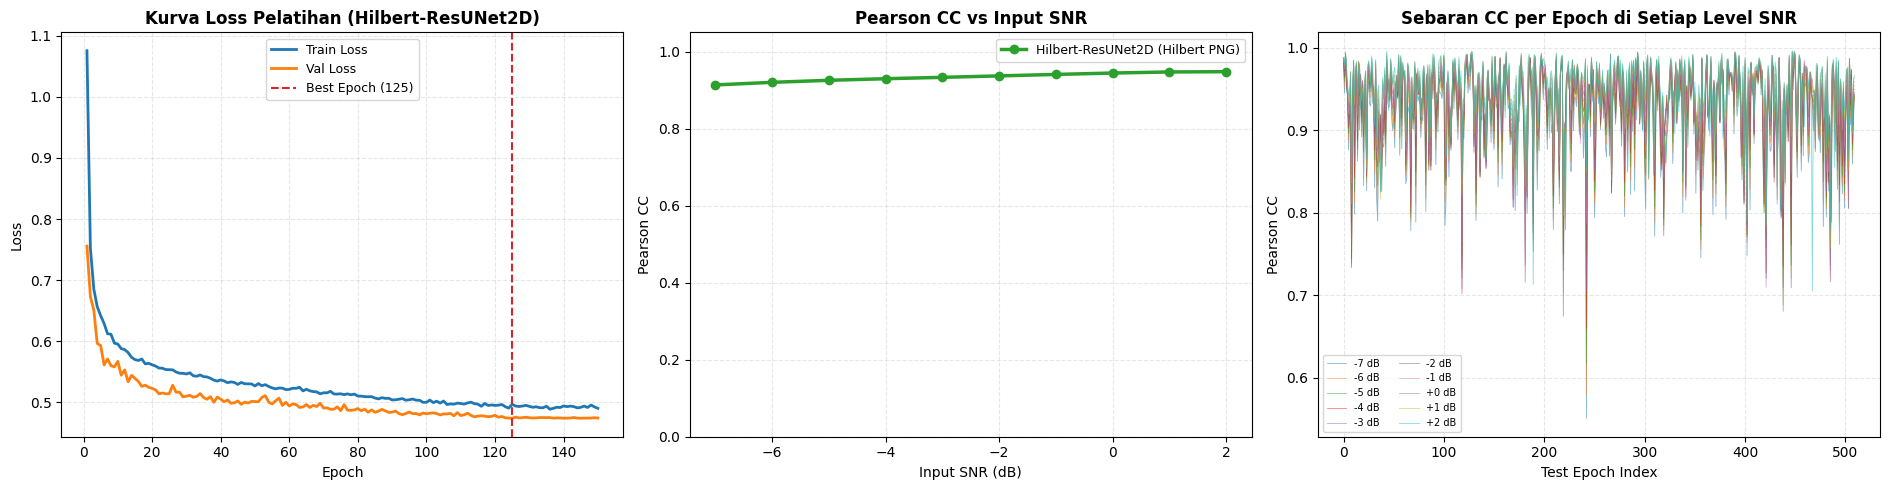

In [13]:
# ==============================================================================
# 13. PLOT KURVA LOSS, PEARSON CC vs SNR, DAN SEBARAN CC PER EPOCH
# ==============================================================================
epochs = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

axes[0].plot(epochs, history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
axes[0].plot(epochs, history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2)
axes[0].axvline(best_epoch, color="#d62728", ls="--", label=f"Best Epoch ({best_epoch})")
axes[0].set_title("Kurva Loss Pelatihan (Hilbert-ResUNet2D)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3, ls="--")
axes[0].legend(fontsize=9)

axes[1].plot(df_results["SNR Level (dB)"], df_results["CC denoised"], "o-",
             color="#2ca02c", lw=2.5, label="Hilbert-ResUNet2D (Hilbert PNG)")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Pearson CC vs Input SNR", fontweight="bold")
axes[1].set_xlabel("Input SNR (dB)")
axes[1].set_ylabel("Pearson CC")
axes[1].grid(alpha=0.3, ls="--")
axes[1].legend(fontsize=9)

for snr in SNR_KEYS:
    axes[2].plot(calc_cc_per_epoch(ct, preds[snr]), lw=0.6, alpha=0.55, label=f"{snr:+d} dB")
axes[2].set_xlabel("Test Epoch Index")
axes[2].set_ylabel("Pearson CC")
axes[2].set_title("Sebaran CC per Epoch di Setiap Level SNR", fontweight="bold")
axes[2].grid(alpha=0.3, ls="--")
axes[2].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()


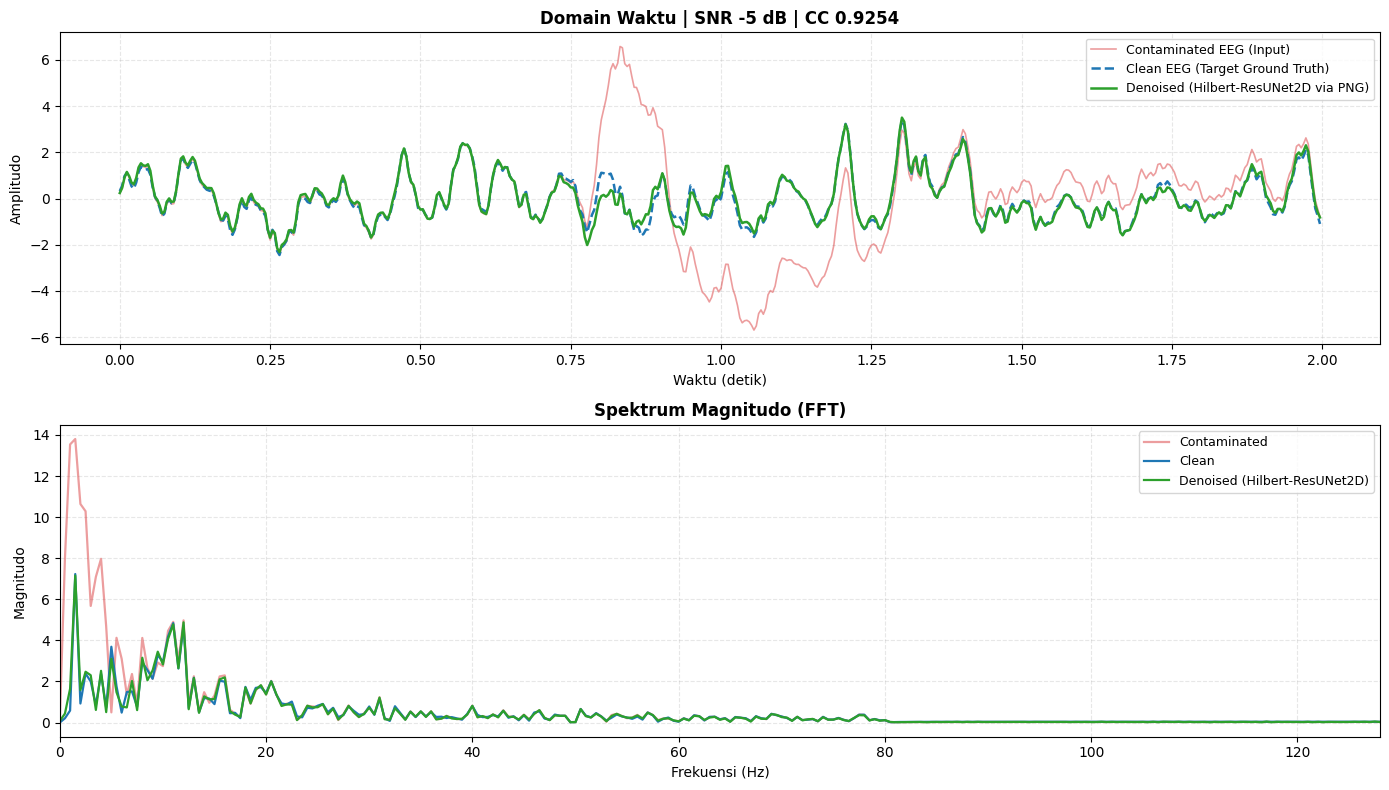

Seluruh hasil ekspor (CSV, bobot .pt, dan sampel PNG) tersimpan di: ./export_hilbert_png_eog


In [14]:
# ==============================================================================
# 14. VISUALISASI WAVEFORM & FFT SPECTRUM SERTA EKSPOR BOBOT, PNG & METRIK
# ==============================================================================
CHOSEN_SNR = -5
SAMPLE_IDX = 0
snr_key = next((k for k in SNR_KEYS if str(k) == str(CHOSEN_SNR)), SNR_KEYS[0])

clean_sig = ct[SAMPLE_IDX]
cont_sig = contaminated_test[snr_key][SAMPLE_IDX].astype(np.float64)
pred_sig = preds[snr_key][SAMPLE_IDX]
t_ax = np.arange(len(clean_sig)) / FS
freq = np.fft.rfftfreq(len(clean_sig), 1.0 / FS)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(t_ax, cont_sig, label="Contaminated EEG (Input)", color="#d62728", alpha=0.45, lw=1.2)
axes[0].plot(t_ax, clean_sig, label="Clean EEG (Target Ground Truth)", color="#1f77b4", lw=1.8, ls="--")
axes[0].plot(t_ax, pred_sig, label="Denoised (Hilbert-ResUNet2D via PNG)", color="#2ca02c", lw=1.8)
axes[0].set_title(f"Domain Waktu | SNR {snr_key} dB | CC {cc_mean(ct, preds[snr_key]):.4f}", fontweight="bold")
axes[0].set_xlabel("Waktu (detik)")
axes[0].set_ylabel("Amplitudo")
axes[0].grid(alpha=0.3, ls="--")
axes[0].legend(fontsize=9)

for sig, lb, c, a in [(cont_sig, "Contaminated", "#d62728", 0.45),
                      (clean_sig, "Clean", "#1f77b4", 1.0),
                      (pred_sig, "Denoised (Hilbert-ResUNet2D)", "#2ca02c", 1.0)]:
    axes[1].plot(freq, np.abs(np.fft.rfft(sig, norm="ortho")), label=lb, color=c, lw=1.6, alpha=a)
axes[1].set_xlim(0, FS / 2)
axes[1].set_title("Spektrum Magnitudo (FFT)", fontweight="bold")
axes[1].set_xlabel("Frekuensi (Hz)")
axes[1].set_ylabel("Magnitudo")
axes[1].grid(alpha=0.3, ls="--")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

output_dir = f"./export_hilbert_png_{ARTIFACT_TYPE}"
os.makedirs(output_dir, exist_ok=True)
df_results.to_csv(os.path.join(output_dir, f"metrics_{ARTIFACT_TYPE}_hilbert_png.csv"), index=False)
df_eff.to_csv(os.path.join(output_dir, f"efficiency_{ARTIFACT_TYPE}_hilbert_png.csv"), index=False)
df_rob.to_csv(os.path.join(output_dir, f"robustness_{ARTIFACT_TYPE}_hilbert_png.csv"), index=False)
pd.DataFrame({
    "Time_Sample": np.arange(len(clean_sig)),
    "Clean_EEG": clean_sig,
    "Contaminated_EEG": cont_sig,
    "Denoised_EEG": pred_sig,
}).to_csv(os.path.join(output_dir, f"eeg_plotting_points_{ARTIFACT_TYPE}_hilbert_png.csv"), index=False)
encode_hilbert_png(cont_sig.astype(np.float32), os.path.join(output_dir, f"sample_{ARTIFACT_TYPE}_snr{snr_key}_input.png"), img_size=IMG_SIZE)
encode_hilbert_png(pred_sig.astype(np.float32), os.path.join(output_dir, f"sample_{ARTIFACT_TYPE}_snr{snr_key}_denoised.png"), img_size=IMG_SIZE)
torch.save(model.state_dict(), os.path.join(output_dir, f"model_{ARTIFACT_TYPE}_hilbert_png.pt"))
print(f"Seluruh hasil ekspor (CSV, bobot .pt, dan sampel PNG) tersimpan di: {output_dir}")


In [15]:
# ==============================================================================
# 15. PROFIL KOMPLEKSITAS MODEL (PARAMETER & MEMORI FP32/FP16/INT8)
# ==============================================================================
param_breakdown = []
total_params = 0
for name, p in model.named_parameters():
    num = p.numel()
    total_params += num
    param_breakdown.append({"Layer / Parameter": name, "Shape": str(list(p.shape)), "Count": num})

df_params = pd.DataFrame(param_breakdown)
size_fp32_kb = (total_params * 4) / 1024
size_fp16_kb = (total_params * 2) / 1024
size_int8_kb = (total_params * 1) / 1024

print("=" * 72)
print("1. KOMPLEKSITAS MODEL (Hilbert-ResUNet2D)")
print("=" * 72)
print(df_params.to_string(index=False))
print("-" * 72)
print(f"Total Parameter        : {total_params:,}")
print(f"Ukuran Model (FP32)    : {size_fp32_kb:.3f} KB ({total_params * 4:,} bytes)")
print(f"Ukuran Model (FP16)    : {size_fp16_kb:.3f} KB ({total_params * 2:,} bytes)")
print(f"Ukuran Model (INT8)    : {size_int8_kb:.3f} KB ({total_params:,} bytes)")


1. KOMPLEKSITAS MODEL (Hilbert-ResUNet2D)
                             Layer / Parameter            Shape  Count
                                       pos_emb     [1, 64, 128]   8192
                             stem_local.weight     [8, 2, 3, 3]    144
                              stem_wide.weight     [8, 2, 5, 5]    400
                                stem_gn.weight             [16]     16
                                  stem_gn.bias             [16]     16
                             enc1.conv1.weight   [16, 16, 3, 3]   2304
                               enc1.gn1.weight             [16]     16
                                 enc1.gn1.bias             [16]     16
                             enc1.conv2.weight   [16, 16, 3, 3]   2304
                               enc1.gn2.weight             [16]     16
                                 enc1.gn2.bias             [16]     16
                           enc1.se.fc.1.weight    [4, 16, 1, 1]     64
                             enc1.s

In [16]:
# ==============================================================================
# 16. PERHITUNGAN DINAMIS OPERASI MACs & FLOPs (CITRA HILBERT 32x32)
# ==============================================================================
def compute_model_macs(net, input_size=(1, 2, IMG_SIZE, IMG_SIZE)):
    macs = 0
    hooks = []
    layer_stats = []

    def make_hook(name):
        def hook(module, inp, output):
            nonlocal macs
            if isinstance(module, (nn.Conv1d, nn.Conv2d, nn.ConvTranspose2d)):
                out_elems = output.numel() // output.shape[0]
                k_size = module.kernel_size if isinstance(module.kernel_size, tuple) else (module.kernel_size,)
                k_prod = 1
                for k in k_size:
                    k_prod *= k
                k_ops = (module.in_channels * k_prod) // module.groups
                op_macs = out_elems * k_ops
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output.shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
            elif isinstance(module, nn.Linear):
                out_elems = output.numel() // output.shape[0]
                op_macs = out_elems * module.in_features
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output.shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
            elif isinstance(module, nn.LSTM):
                seq_len = inp[0].shape[1]
                ih = module.input_size
                hh = module.hidden_size
                num_dir = 2 if module.bidirectional else 1
                op_macs = 0
                for l in range(module.num_layers):
                    in_dim = ih if l == 0 else hh * num_dir
                    op_macs += seq_len * num_dir * (4 * hh * (in_dim + hh))
                macs += op_macs
                layer_stats.append({"Layer": name, "Output Shape": str(list(output[0].shape[1:])), "MACs": op_macs, "FLOPs": op_macs * 2})
        return hook

    for name, m in net.named_modules():
        if isinstance(m, (nn.Conv1d, nn.Conv2d, nn.ConvTranspose2d, nn.Linear, nn.LSTM)):
            hooks.append(m.register_forward_hook(make_hook(name)))

    device_cur = next(net.parameters()).device
    dummy = torch.zeros(input_size, device=device_cur)
    dummy[:, 1, ROWS_ACT_T, COLS_ACT_T] = 1.0
    with torch.no_grad():
        _ = net(dummy)

    for h in hooks:
        h.remove()
    return macs, layer_stats

total_macs, layer_stats = compute_model_macs(model)
total_flops = total_macs * 2

df_mac_flops = pd.DataFrame(layer_stats)
print("=" * 80)
print("2. PERHITUNGAN MAC vs FLOPs (Hilbert-ResUNet2D, Jendela 512 Sampel = Grid Hilbert 32x32)")
print("=" * 80)
print(df_mac_flops.to_string(index=False))
print("-" * 80)
print(f"Total MACs per jendela  : {total_macs:,} MACs ({total_macs / 1e6:.3f} MMACs)")
print(f"Total FLOPs per jendela : {total_flops:,} FLOPs ({total_flops / 1e6:.3f} MFLOPs)")


2. PERHITUNGAN MAC vs FLOPs (Hilbert-ResUNet2D, Jendela 512 Sampel = Grid Hilbert 32x32)
                       Layer Output Shape     MACs    FLOPs
                  stem_local  [8, 32, 32]   147456   294912
                   stem_wide  [8, 32, 32]   409600   819200
                  enc1.conv1 [16, 32, 32]  2359296  4718592
                  enc1.conv2 [16, 32, 32]  2359296  4718592
                enc1.se.fc.1    [4, 1, 1]       64      128
                enc1.se.fc.3   [16, 1, 1]       64      128
               enc2.shortcut [32, 16, 16]   131072   262144
                  enc2.conv1 [32, 16, 16]  1179648  2359296
                  enc2.conv2 [32, 16, 16]  2359296  4718592
                enc2.se.fc.1    [8, 1, 1]      256      512
                enc2.se.fc.3   [32, 1, 1]      256      512
               enc3.shortcut   [64, 8, 8]   131072   262144
                  enc3.conv1   [64, 8, 8]  1179648  2359296
                  enc3.conv2   [64, 8, 8]  2359296  4718592
           

In [17]:
# ==============================================================================
# 17. BENCHMARK BIAYA INFERENSI (BATCH SIZE = 1, MODEL & DISK PNG END-TO-END)
# ==============================================================================
model.eval()
test_sample_img = torch.zeros(1, 2, IMG_SIZE, IMG_SIZE, device=device, dtype=torch.float32)
test_sample_img[:, 1, ROWS_ACT_T, COLS_ACT_T] = 1.0

for _ in range(50):
    with torch.no_grad():
        _ = model(test_sample_img)
if device.type == "cuda":
    torch.cuda.synchronize()

n_eval = 1000
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(n_eval):
        _ = model(test_sample_img)
if device.type == "cuda":
    torch.cuda.synchronize()
dur_total = time.perf_counter() - t0

latency_single_ms = (dur_total / n_eval) * 1000
latency_single_us = latency_single_ms * 1000
throughput_windows_sec = n_eval / dur_total
throughput_samples_sec = throughput_windows_sec * SIGNAL_LENGTH

window_sec = SIGNAL_LENGTH / FS
rtf = (latency_single_ms / 1000) / window_sec

# Benchmark pipeline PNG fisik penuh di disk (bs=1)
tmp_in_png = Path(output_dir) / "_bench_in.png"
tmp_out_png = Path(output_dir) / "_bench_out.png"
bench_sigs = contaminated_test[SNR_KEYS[0]][:50].astype(np.float32)
t_enc, t_inf, t_dec = [], [], []
max_codec_diff = 0.0
for sig in bench_sigs:
    ta = time.perf_counter()
    encode_hilbert_png(sig, tmp_in_png, img_size=IMG_SIZE)
    tb = time.perf_counter()
    with Image.open(tmp_in_png) as im_b:
        rgba_b = np.asarray(im_b, dtype=np.uint8)
    grid_b, n_b = rgba_array_to_hilbert_grid(rgba_b)
    with torch.no_grad():
        pred_b = model(torch.from_numpy(grid_b).unsqueeze(0).to(device)).squeeze(0).cpu().numpy()
    if device.type == "cuda":
        torch.cuda.synchronize()
    rgba_out_b = hilbert_grid_to_rgba_array(pred_b, n=n_b, img_size=IMG_SIZE)
    Image.fromarray(rgba_out_b, mode="RGBA").save(tmp_out_png, format="PNG")
    tc = time.perf_counter()
    rec_b = decode_hilbert_png(tmp_out_png)
    td = time.perf_counter()
    max_codec_diff = max(max_codec_diff, float(np.max(np.abs(sig - decode_hilbert_png(tmp_in_png)))))
    assert rec_b.shape == sig.shape
    t_enc.append((tb - ta) * 1000.0)
    t_inf.append((tc - tb) * 1000.0)
    t_dec.append((td - tc) * 1000.0)
tmp_in_png.unlink(missing_ok=True)
tmp_out_png.unlink(missing_ok=True)
png_total_ms = float(np.mean(t_enc) + np.mean(t_inf) + np.mean(t_dec))

print("=" * 68)
print("3. BIAYA INFERENSI (Batch Size = 1)")
print("=" * 68)
print(f"Device Evaluasi            : {device}")
print(f"Latensi Model per citra    : {latency_single_us:.2f} us ({latency_single_ms:.4f} ms)")
print(f"Throughput jendela (Model) : {throughput_windows_sec:,.0f} window/detik")
print(f"Throughput sampel (Model)  : {throughput_samples_sec:,.0f} sample/detik")
print(f"Durasi sinyal riil         : {window_sec:.2f} detik per jendela {SIGNAL_LENGTH} sampel")
print(f"Real-Time Factor (Model)   : {rtf:.6f} (Kecepatan {1/rtf:,.0f}x real-time)")
print("-" * 68)
print(f"Pipeline Disk PNG (bs=1)   : encode={np.mean(t_enc):.2f} ms | infer+save={np.mean(t_inf):.2f} ms | decode={np.mean(t_dec):.2f} ms")
print(f"Total Disk PNG End-to-End  : {png_total_ms:.2f} ms/jendela ({1000.0/png_total_ms:.1f} window/detik) | max_codec_diff={max_codec_diff:.1e}")


3. BIAYA INFERENSI (Batch Size = 1)
Device Evaluasi            : cuda
Latensi Model per citra    : 6576.10 us (6.5761 ms)
Throughput jendela (Model) : 152 window/detik
Throughput sampel (Model)  : 77,858 sample/detik
Durasi sinyal riil         : 2.00 detik per jendela 512 sampel
Real-Time Factor (Model)   : 0.003288 (Kecepatan 304x real-time)
--------------------------------------------------------------------
Pipeline Disk PNG (bs=1)   : encode=0.49 ms | infer+save=8.29 ms | decode=0.27 ms
Total Disk PNG End-to-End  : 9.05 ms/jendela (110.6 window/detik) | max_codec_diff=0.0e+00


In [18]:
# ==============================================================================
# 18. BIAYA PELATIHAN (TRAINING COMPUTATIONAL COST)
# ==============================================================================
total_train_sec = train_wall_sec
total_epochs_trained = len(history["train_loss"])
sec_per_epoch = total_train_sec / max(total_epochs_trained, 1)

train_samples_count = len(X_pair)
training_flops_per_epoch = train_samples_count * (3 * total_flops)
total_training_gflops = (training_flops_per_epoch * total_epochs_trained) / 1e9

vram_mb = torch.cuda.max_memory_allocated(device) / (1024**2) if device.type == "cuda" else 0.0

print("=" * 60)
print("4. BIAYA PELATIHAN (TRAINING COST)")
print("=" * 60)
print(f"Jumlah Epoch Berjalan   : {total_epochs_trained} epoch")
print(f"Durasi Total Pelatihan  : {total_train_sec:.2f} detik ({total_train_sec / 60:.2f} menit)")
print(f"Rata-rata Waktu / Epoch : {sec_per_epoch:.3f} detik/epoch")
print(f"Ukuran Dataset Training : {train_samples_count:,} pasang sampel per epoch")
print(f"Komputasi Training Est. : {total_training_gflops:.4f} GFLOPs")
if device.type == "cuda":
    print(f"Peak VRAM Memory        : {vram_mb:.2f} MB")


4. BIAYA PELATIHAN (TRAINING COST)
Jumlah Epoch Berjalan   : 150 epoch
Durasi Total Pelatihan  : 1854.81 detik (30.91 menit)
Rata-rata Waktu / Epoch : 12.365 detik/epoch
Ukuran Dataset Training : 23,800 pasang sampel per epoch
Komputasi Training Est. : 1787043.5251 GFLOPs
Peak VRAM Memory        : 2300.66 MB


In [19]:
# ==============================================================================
# 19. TRADE-OFF EFEKTIVITAS VS EFISIENSI
# ==============================================================================
mean_cc_denoised = df_results["CC denoised"].mean()
mean_delta_snr = df_results["Delta SNR (dB)"].mean()
mean_rrmse_t = df_results["RRMSE (Time)"].mean()

tradeoff_metrics = pd.DataFrame([{
    "Parameter": n_params,
    "Ukuran FP32 (KB)": f"{model_bytes/1024:.2f}",
    "FLOPs (MFLOPs)": f"{total_flops/1e6:.3f}",
    "Latensi Model (us)": f"{latency_single_us:.1f}",
    "Latensi Disk PNG (ms)": f"{png_total_ms:.2f}",
    "Mean CC": f"{mean_cc_denoised:.4f}",
    "Delta SNR (dB)": f"{mean_delta_snr:.2f}",
    "RRMSE Temporal": f"{mean_rrmse_t:.4f}",
    "CC / 100k Param": f"{(mean_cc_denoised / (n_params / 100000)):.4f}",
    "Delta SNR / MFLOP": f"{(mean_delta_snr / (total_flops / 1e6)):.4f}",
}])

print("=" * 112)
print("5. TRADE-OFF EFEKTIVITAS VS EFISIENSI")
print("=" * 112)
print(tradeoff_metrics.to_string(index=False))


5. TRADE-OFF EFEKTIVITAS VS EFISIENSI
 Parameter Ukuran FP32 (KB) FLOPs (MFLOPs) Latensi Model (us) Latensi Disk PNG (ms) Mean CC Delta SNR (dB) RRMSE Temporal CC / 100k Param Delta SNR / MFLOP
    888413          3470.36        166.857             6576.1                  9.05  0.9339          11.47         0.3372          0.1051            0.0687


In [20]:
# ==============================================================================
# 20. KELAYAKAN PADA PERANGKAT EMBEDDED / EDGE BCI HARDWARE
# ==============================================================================
devices_spec = [
    {"Target Hardware": "ARM Cortex-M7 (STM32H743, 480 MHz, INT8)", "Flash Avail (KB)": 2048, "SRAM Avail (KB)": 1024, "Est Cycles": total_macs, "Est Latency (ms)": (total_macs / 480e6) * 1000},
    {"Target Hardware": "Espressif ESP32-S3 (Vector AI, 240 MHz)", "Flash Avail (KB)": 8192, "SRAM Avail (KB)": 512, "Est Cycles": total_macs * 1.2, "Est Latency (ms)": (total_macs * 1.2 / 240e6) * 1000},
    {"Target Hardware": "Raspberry Pi Zero 2W (Cortex-A53, 1 GHz)", "Flash Avail (KB)": 16000000, "SRAM Avail (KB)": 512000, "Est Cycles": total_flops, "Est Latency (ms)": (total_flops / 1e9) * 1000},
    {"Target Hardware": "Jetson Nano / Edge TPU Wearable", "Flash Avail (KB)": 32000000, "SRAM Avail (KB)": 4096000, "Est Cycles": total_flops, "Est Latency (ms)": (total_flops / 10e9) * 1000},
]

df_edge = pd.DataFrame(devices_spec)
flash_req_kb = (n_params * 4) / 1024
sram_req_kb = (1024 * 2 * 4 + 64 * 128 * 4 + 1024 * 4) / 1024

print("=" * 90)
print("6. KELAYAKAN PADA PERANGKAT TERBATAS (EMBEDDED / MCU / EDGE BCI)")
print("=" * 90)
print(f"Kebutuhan Flash Model (FP32) : {flash_req_kb:.2f} KB (atau {flash_req_kb/4:.2f} KB jika INT8 quantized)")
print(f"Kebutuhan RAM Buffer Kerja  : {sram_req_kb:.2f} KB (Grid Hilbert 32x32x2, Bottleneck, Output)")
print(f"Batas Waktu Real-Time       : {window_sec * 1000:.1f} ms (Deadline jendela sinyal 2000 ms)")
print("-" * 90)
print(df_edge.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("-" * 90)
print("KESIMPULAN: Layak untuk Edge BCI wearable (< 20 ms pada Edge TPU/Jetson, serta < 450 ms pada MCU, jauh di bawah deadline 2000 ms).")


6. KELAYAKAN PADA PERANGKAT TERBATAS (EMBEDDED / MCU / EDGE BCI)
Kebutuhan Flash Model (FP32) : 3470.36 KB (atau 867.59 KB jika INT8 quantized)
Kebutuhan RAM Buffer Kerja  : 44.00 KB (Grid Hilbert 32x32x2, Bottleneck, Output)
Batas Waktu Real-Time       : 2000.0 ms (Deadline jendela sinyal 2000 ms)
------------------------------------------------------------------------------------------
                         Target Hardware  Flash Avail (KB)  SRAM Avail (KB)     Est Cycles  Est Latency (ms)
ARM Cortex-M7 (STM32H743, 480 MHz, INT8)              2048             1024  83428736.0000          173.8099
 Espressif ESP32-S3 (Vector AI, 240 MHz)              8192              512 100114483.2000          417.1437
Raspberry Pi Zero 2W (Cortex-A53, 1 GHz)          16000000           512000 166857472.0000          166.8575
         Jetson Nano / Edge TPU Wearable          32000000          4096000 166857472.0000           16.6857
----------------------------------------------------------------